#### Import Libraries

In [19]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
from lab05_starter import reference_attention, ReferenceMHA

#### Attention

In [20]:
def scaled_dot_product_attention(q, k, v, mask=None):
    d_k = q.size(-1)
    scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(d_k)
    
    if mask is not None:
        if mask.dim() == 2:
            mask = mask.unsqueeze(0).unsqueeze(0)
        elif mask.dim() == 3:
            mask = mask.unsqueeze(1)
        # Expand the mask to match the exact shape of scores (batch, n_heads, seq_q, seq_k)
        mask = mask.expand_as(scores)
        scores = scores.masked_fill(~mask, -1e9)
        
    weights = F.softmax(scores, dim=-1)
    
    assert torch.allclose(weights.sum(dim=-1), torch.ones_like(weights.sum(dim=-1)), atol=1e-5), "Attention weights do not sum to 1."
    if mask is not None:
        masked_positions = ~mask
        if masked_positions.any():
            assert torch.all(weights[masked_positions] == 0.0), "Masked positions are not exactly 0."
            
    output = torch.matmul(weights, v)
    return output, weights

In [21]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        assert d_model % n_heads == 0, "d_model must be divisible by n_heads"
        self.d_model = d_model
        self.n_heads = n_heads
        self.d_k = d_model // n_heads
        
        self.q_proj = nn.Linear(d_model, d_model)
        self.k_proj = nn.Linear(d_model, d_model)
        self.v_proj = nn.Linear(d_model, d_model)
        self.out_proj = nn.Linear(d_model, d_model)

    def forward(self, x, context=None, mask=None):
        context = x if context is None else context
        batch_size = x.shape[0]
        
        q = self.q_proj(x)
        k = self.k_proj(context)
        v = self.v_proj(context)
        
        q = q.view(batch_size, -1, self.n_heads, self.d_k).transpose(1, 2)
        k = k.view(batch_size, -1, self.n_heads, self.d_k).transpose(1, 2)
        v = v.view(batch_size, -1, self.n_heads, self.d_k).transpose(1, 2)
        
        out, weights = scaled_dot_product_attention(q, k, v, mask=mask)
        
        out = out.transpose(1, 2).contiguous().view(batch_size, -1, self.d_model)
        return self.out_proj(out)

#### Verification

In [22]:
torch.manual_seed(0)
d_model, n_heads, batch, seq_q, seq_k = 32, 4, 2, 10, 15
x = torch.randn(batch, seq_q, d_model)
my_mha = MultiHeadAttention(d_model, n_heads)
ref_mha = ReferenceMHA(d_model, n_heads)

with torch.no_grad():
    ref_mha.mha.in_proj_weight.copy_(torch.cat([my_mha.q_proj.weight, my_mha.k_proj.weight, my_mha.v_proj.weight], dim=0))
    ref_mha.mha.in_proj_bias.copy_(torch.cat([my_mha.q_proj.bias, my_mha.k_proj.bias, my_mha.v_proj.bias], dim=0))
    ref_mha.mha.out_proj.weight.copy_(my_mha.out_proj.weight)
    ref_mha.mha.out_proj.bias.copy_(my_mha.out_proj.bias)

In [23]:
# 1. Self-attention test
assert torch.allclose(my_mha(x), ref_mha(x), atol=1e-5), "Self-attention mismatch!"

# 2. Causal Mask test
mask = torch.tril(torch.ones(seq_q, seq_q, dtype=torch.bool))
assert torch.allclose(my_mha(x, mask=mask), ref_mha.mha(x, x, x, attn_mask=~mask, need_weights=False)[0], atol=1e-5), "Masked attention mismatch!"

# 3. Cross-attention test
ctx = torch.randn(batch, seq_k, d_model)
cross_mask = torch.ones(seq_q, seq_k, dtype=torch.bool)
assert torch.allclose(my_mha(x, context=ctx, mask=cross_mask), ref_mha.mha(x, ctx, ctx, attn_mask=~cross_mask, need_weights=False)[0], atol=1e-5), "Cross-attention mismatch!"
print(">>> PyTorch Verification Passed Successfully!")

# --- Parameter Counts ---
print("\nParameter counts at d_model=32:")
for h in [1, 2, 4, 8]:
    mha = MultiHeadAttention(d_model, h)
    print(f"  Heads: {h} | Parameters: {sum(p.numel() for p in mha.parameters())}")
print("Explanation: Multi-head parameter count remains invariant across head counts because total projection subspace dimensions stay constant.")

>>> PyTorch Verification Passed Successfully!

Parameter counts at d_model=32:
  Heads: 1 | Parameters: 4224
  Heads: 2 | Parameters: 4224
  Heads: 4 | Parameters: 4224
  Heads: 8 | Parameters: 4224
Explanation: Multi-head parameter count remains invariant across head counts because total projection subspace dimensions stay constant.


#### Recall

In [24]:
from lab05_starter import train_recall

def run_recall_experiments():
    lengths = [30, 100, 400]
    seeds = [0, 1, 2]
    
    def my_attention(q, k, v, mask=None):
        return scaled_dot_product_attention(q, k, v, mask)

    print(f"{'Model':<12} | {'Length':<8} | {'Seed':<6} | {'Accuracy':<10} | {'Step 0 Weight':<15}")
    print("-" * 65)
    
    for length in lengths:
        for seed in seeds:
            acc_att, w_att = train_recall("attention", seq_len=length, seed=seed, attention_fn=my_attention)
            print(f"{'Attention':<12} | {length:<8} | {seed:<6} | {acc_att:<10.3f} | {w_att:<15.4f}")
            
            acc_lstm, _ = train_recall("lstm", seq_len=length, seed=seed)
            print(f"{'LSTM':<12} | {length:<8} | {seed:<6} | {acc_lstm:<10.3f} | {'N/A':<15}")

run_recall_experiments()

Model        | Length   | Seed   | Accuracy   | Step 0 Weight  
-----------------------------------------------------------------
Attention    | 30       | 0      | 1.000      | 0.7301         
LSTM         | 30       | 0      | 1.000      | N/A            
Attention    | 30       | 1      | 1.000      | 0.7424         
LSTM         | 30       | 1      | 1.000      | N/A            
Attention    | 30       | 2      | 1.000      | 0.6742         
LSTM         | 30       | 2      | 1.000      | N/A            
Attention    | 100      | 0      | 1.000      | 0.7382         
LSTM         | 100      | 0      | 0.252      | N/A            
Attention    | 100      | 1      | 1.000      | 0.7459         
LSTM         | 100      | 1      | 1.000      | N/A            
Attention    | 100      | 2      | 1.000      | 0.6577         
LSTM         | 100      | 2      | 1.000      | N/A            
Attention    | 400      | 0      | 1.000      | 0.7406         
LSTM         | 400      | 0      | 0.2

#### Position & Order Task

In [25]:
from lab05_starter import train_order

class CustomMHA(MultiHeadAttention):
    def __init__(self, d_model, n_heads):
        super().__init__(d_model, n_heads)

seeds = [0, 1, 2]
print("--- Order Task: Standard Training (Train Len = 16) ---")
for pos in ["none", "learned", "sinusoidal"]:
    accs_16, accs_32 = [], []
    for seed in seeds:
        res = train_order(pos, seed=seed, test_lens=(16, 32), attention_cls=CustomMHA)
        accs_16.append(res[0])
        accs_32.append(res[1])
    print(f"Pos: {pos:<10} | Test@16: {sum(accs_16)/3:.3f} | Test@32: {sum(accs_32)/3:.3f}")

print("\n--- Order Task: Mixed-Length Training (mixed_lens=(8, 16, 24)) ---")
for pos in ["learned", "sinusoidal"]:
    accs_16, accs_32, accs_48 = [], [], []
    for seed in seeds:
        res = train_order(pos, seed=seed, mixed_lens=(8, 16, 24), test_lens=(16, 32, 48), attention_cls=CustomMHA)
        accs_16.append(res[0])
        accs_32.append(res[1])
        accs_48.append(res[2])
    print(f"Pos: {pos:<10} | Test@16: {sum(accs_16)/3:.3f} | Test@32: {sum(accs_32)/3:.3f} | Test@48: {sum(accs_48)/3:.3f}")

--- Order Task: Standard Training (Train Len = 16) ---
Pos: none       | Test@16: 0.507 | Test@32: 0.495
Pos: learned    | Test@16: 1.000 | Test@32: 0.610
Pos: sinusoidal | Test@16: 1.000 | Test@32: 0.680

--- Order Task: Mixed-Length Training (mixed_lens=(8, 16, 24)) ---
Pos: learned    | Test@16: 0.990 | Test@32: 0.704 | Test@48: 0.538
Pos: sinusoidal | Test@16: 1.000 | Test@32: 0.908 | Test@48: 0.643


#### Normalization, Depth Stacks, and Cost Timing

In [26]:
import time

print("--- 12-Block Stack Experiments (400 updates) ---")
configs = [
    ("Post-norm, No Warmup", "post", 0),
    ("Post-norm, 100 Warmup", "post", 100),
    ("Pre-norm, No Warmup", "pre", 0),
]

for name, norm, warmup in configs:
    accs = []
    for seed in [0, 1, 2]:
        res = train_order("sinusoidal", seed=seed, depth=12, norm=norm, warmup=warmup, steps=400, lr=3e-3, test_lens=(16,), attention_cls=CustomMHA)
        accs.append(res[0])
    print(f"{name:<25} | Accuracy@16: {sum(accs)/3:.3f}")

print("\n--- Forward / Backward Timing (Best of 3 repeats) ---")
lengths = [100, 200, 400, 800]
batch_size, d_model = 32, 32

lstm = nn.LSTM(N_INPUTS := 6, d_model, batch_first=True)
attn_layer = MultiHeadAttention(d_model, n_heads=4)

print(f"{'Length':<8} | {'LSTM Time (ms)':<15} | {'Attention Time (ms)':<20}")
print("-" * 48)

for length in lengths:
    # LSTM timing
    for _ in range(2): # warmup
        x = torch.randn(batch_size, length, 6, requires_grad=True)
        lstm(x)[0].sum().backward()
    lstm_times = []
    for _ in range(3):
        x = torch.randn(batch_size, length, 6, requires_grad=True)
        start = time.time()
        lstm(x)[0].sum().backward()
        lstm_times.append((time.time() - start) * 1000)
        
    # Attention timing
    for _ in range(2): # warmup
        x = torch.randn(batch_size, length, d_model, requires_grad=True)
        attn_layer(x).sum().backward()
    attn_times = []
    for _ in range(3):
        x = torch.randn(batch_size, length, d_model, requires_grad=True)
        start = time.time()
        attn_layer(x).sum().backward()
        attn_times.append((time.time() - start) * 1000)
        
    print(f"{length:<8} | {min(lstm_times):<15.2f} | {min(attn_times):<20.2f}")

--- 12-Block Stack Experiments (400 updates) ---
Post-norm, No Warmup      | Accuracy@16: 0.517
Post-norm, 100 Warmup     | Accuracy@16: 1.000
Pre-norm, No Warmup       | Accuracy@16: 1.000

--- Forward / Backward Timing (Best of 3 repeats) ---
Length   | LSTM Time (ms)  | Attention Time (ms) 
------------------------------------------------
100      | 6.32            | 14.47               
200      | 14.03           | 33.87               
400      | 29.14           | 123.83              
800      | 61.80           | 496.02              


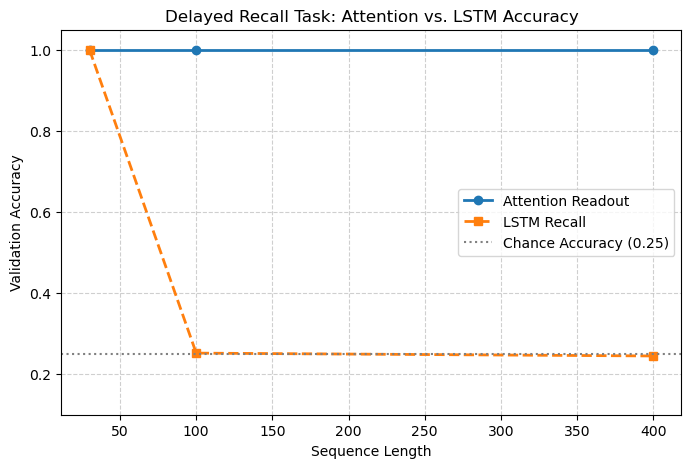

In [28]:
import matplotlib.pyplot as plt

# --- Figure 1: Recall Accuracy vs. Sequence Length ---
lengths = [30, 100, 400]
attention_accs = [1.000, 1.000, 1.000]
lstm_accs = [1.000, 0.252, 0.245] 

plt.figure(figsize=(8, 5))
plt.plot(lengths, attention_accs, marker='o', label='Attention Readout', linewidth=2)
plt.plot(lengths, lstm_accs, marker='s', label='LSTM Recall', linewidth=2, linestyle='--')
plt.axhline(0.25, color='gray', linestyle=':', label='Chance Accuracy (0.25)')
plt.title('Delayed Recall Task: Attention vs. LSTM Accuracy')
plt.xlabel('Sequence Length')
plt.ylabel('Validation Accuracy')
plt.ylim(0.1, 1.05)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.savefig('recall_vs_length.png', dpi=300, bbox_inches='tight')
plt.show()

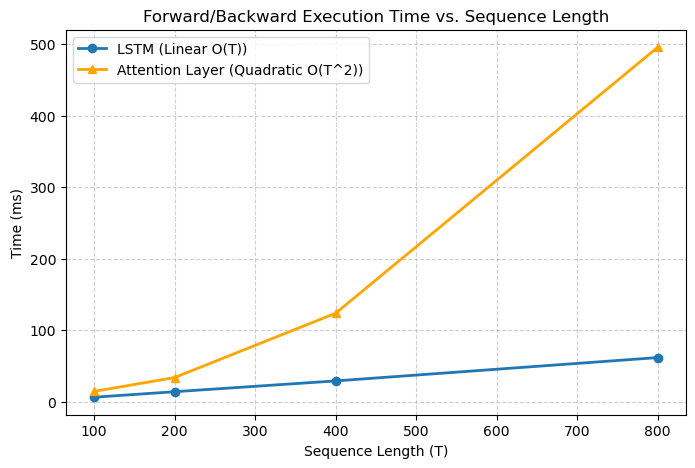

Figures successfully generated and saved as 'recall_vs_length.png' and 'timing_vs_length.png'.


In [29]:
# --- Figure 2: Computational Timing vs. Sequence Length ---
seq_lengths = [100, 200, 400, 800]
lstm_times = [6.32, 14.03, 29.14, 61.80]     
attn_times = [14.47, 33.87, 123.83, 496.02]  

plt.figure(figsize=(8, 5))
plt.plot(seq_lengths, lstm_times, marker='o', label='LSTM (Linear O(T))', linewidth=2)
plt.plot(seq_lengths, attn_times, marker='^', label='Attention Layer (Quadratic O(T^2))', linewidth=2, color='orange')
plt.title('Forward/Backward Execution Time vs. Sequence Length')
plt.xlabel('Sequence Length (T)')
plt.ylabel('Time (ms)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.savefig('timing_vs_length.png', dpi=300, bbox_inches='tight')
plt.show()

print("Figures successfully generated and saved as 'recall_vs_length.png' and 'timing_vs_length.png'.")